# ZerO / ResNet-18: анализ серверных результатов

Обучение находится в Python-модулях. Notebook читает экспорт `runs/`, строит графики и анализирует их; обучение не запускается.

[Отчёт о воспроизведении (PDF)](../REPORT.pdf).

Имеются три 200-epoch запуска seed0 и шесть 400-step Figure8 runs. Истории эпох не перенесены: Figure5/training показаны как архивные изображения с пояснением об отсутствии сырых логов. Compression есть для ZerO/Xavier; Kaiming отсутствует. MNIST Figure 3 добавлена в mlp_ZeRO.ipynb и ../REPORT.pdf.

In [1]:
from pathlib import Path
import sys, json
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image as DisplayImage
BASE = Path.cwd()
if not (BASE / "zero_experiments").exists():
    BASE = next(p for p in (BASE / "reproduction", BASE / "hw2/reproduction",
                            BASE / "efficient-nn-hw/hw2/reproduction")
                if (p / "zero_experiments").exists())
sys.path.insert(0, str(BASE))
from zero_experiments.results import aggregate, read_csv, report
from zero_experiments.plotting import figure5, figure6, figure8, training_curves, load_gradient_rows

# Выбираем существующие результаты; эти пути можно задать вручную.
ROOT = next((p for p in (BASE / "runs/main", BASE / "runs/reproduction-smoke")
             if any(p.glob("resnet18-*/history.csv"))), BASE / "runs")
GRADIENT_ROOT = next((p for p in (BASE / "runs/figure8", ROOT / "figure8", BASE / "runs/figure8-smoke", ROOT)
                      if (p / "gradients.csv").is_file() or (p / "gradients.json").is_file()),
                     BASE / "runs/figure8")
print("Основные результаты:", ROOT)
print("Данные Figure 8:", GRADIENT_ROOT)

Основные результаты: /Users/ilya/Documents/compet/itmo/efficient-nn-hw/hw2/reproduction/runs
Данные Figure 8: /Users/ilya/Documents/compet/itmo/efficient-nn-hw/hw2/reproduction/runs/figure8


## Фактические запуски и статистика

Sample std: ddof=1. 95% CI: Student-t. При n=1 std/CI не определены. Основной checkpoint — последняя эпоха; best observed test — отдельная описательная верхняя оценка, не критерий настройки.

In [2]:
stats, paired, runs = aggregate(ROOT)
print(json.dumps(stats, ensure_ascii=False, indent=2))
print("Парные разности ошибок ZerO−alternative:")
print(json.dumps(paired, ensure_ascii=False, indent=2))
for r in runs:
    print(r["method"], "seed", r["seed"], "epochs", r["epochs"],
          "test error", r["test_error"], "train seconds", r["train_seconds"],
          "process peak RSS MB", r["process_peak_rss_mb"])
if any(r["smoke"] for r in runs):
    display(Markdown("**SMOKE: короткое обучение не является результатом Table 2.**"))

[
  {
    "method": "kaiming",
    "n": 1,
    "mean": 4.890000000000006,
    "std": null,
    "ci_low": null,
    "ci_high": null,
    "std_ddof": 1,
    "ci_method": "Student-t 95%",
    "seeds": "0",
    "smoke": false,
    "paper_reference_error": 5.15,
    "paper_reference_std": 0.13,
    "difference_pp": -0.25999999999999446
  },
  {
    "method": "xavier",
    "n": 1,
    "mean": 5.020000000000002,
    "std": null,
    "ci_low": null,
    "ci_high": null,
    "std_ddof": 1,
    "ci_method": "Student-t 95%",
    "seeds": "0",
    "smoke": false,
    "paper_reference_error": 5.23,
    "paper_reference_std": 0.16,
    "difference_pp": -0.2099999999999982
  },
  {
    "method": "zero",
    "n": 1,
    "mean": 13.290000000000003,
    "std": null,
    "ci_low": null,
    "ci_high": null,
    "std_ddof": 1,
    "ci_method": "Student-t 95%",
    "seeds": "0",
    "smoke": false,
    "paper_reference_error": 5.13,
    "paper_reference_std": 0.08,
    "difference_pp": 8.160000000000004
  

## Figure 5 — 3 панели, верхний ряд

Слои `layer2.0.conv1`, `layer3.0.conv1`, `layer4.0.conv1`: первые свёртки второй, третьей и четвёртой групп. Stable rank = Σσ²/σmax². Измерения до обучения и после каждой эпохи; CSV: method, seed, epoch, layer, stable_rank. Новые запуски сохраняют ядра в `rank_weights/epoch-*.pt`; в переданном серверном экспорте их нет.

Развёртка `[Cout,Cin*kH*kW]` выбрана до эксперимента как реконструкция, поскольку авторский conv-analysis код отсутствует. Identity не вычитается. Для нулевого ядра используется документированное значение 0.

**Figure5: сырые ranks.csv отсутствуют. Показан серверный экспорт до 200 эпох.**

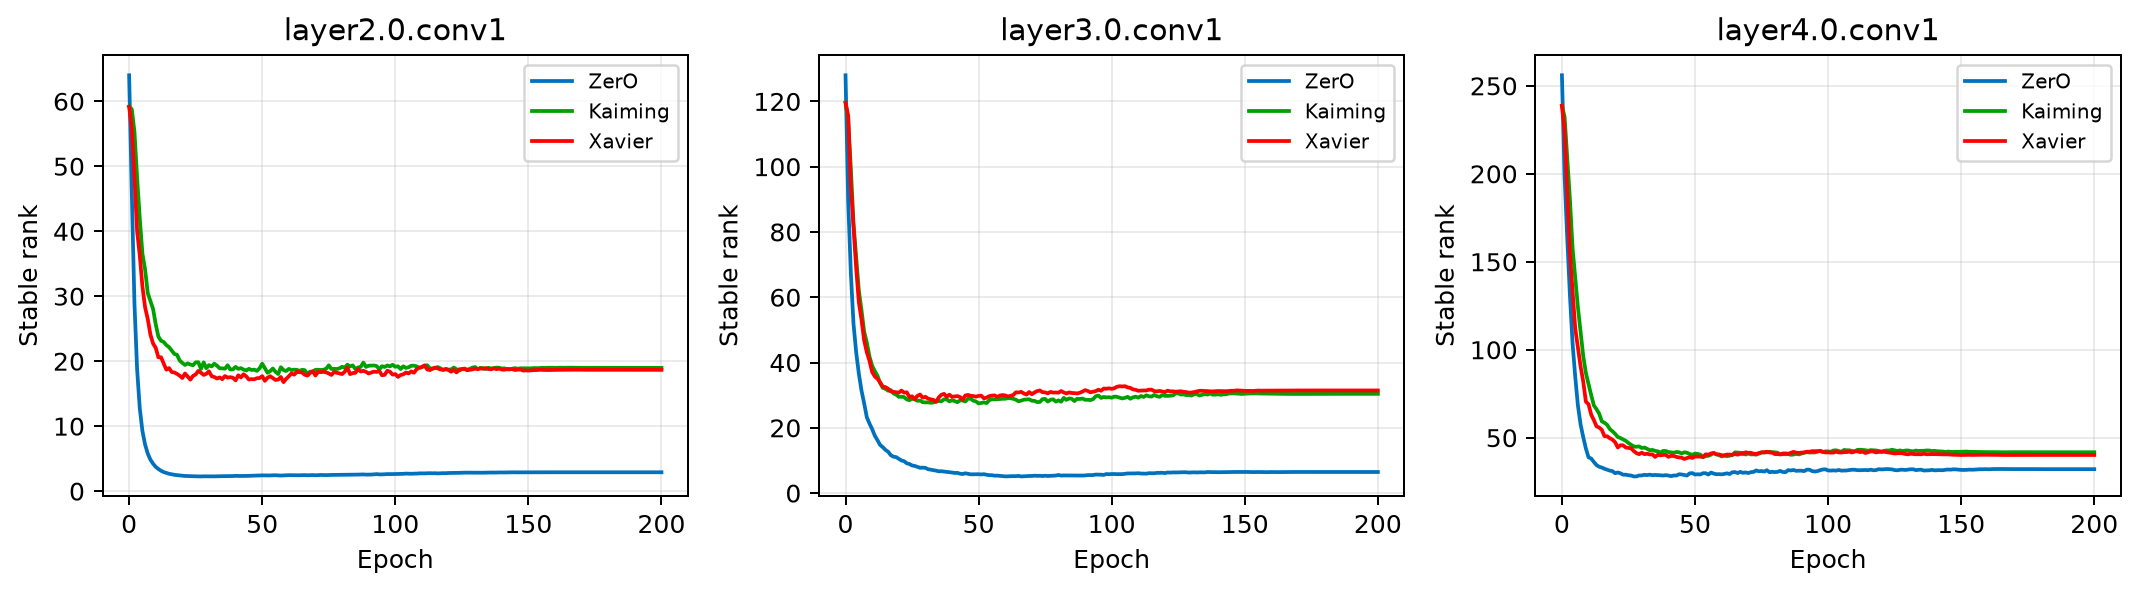

In [3]:
try:
    fig = figure5(ROOT)
    display(fig)
    plt.close(fig)
except FileNotFoundError as error:
    display(Markdown("**Figure5: сырые ranks.csv отсутствуют. Показан серверный экспорт до 200 эпох.**"))
    image = ROOT / "plots/figure5-resnet18.png"
    if image.exists():
        display(DisplayImage(filename=str(image)))
    else:
        print(error)

## Figure 6 — 3 панели

Слева — stem и 16 residual Conv, без projection shortcuts. Используется **stable rank** по §5; отдельный алгоритм Kernel Rank не опубликован. Mapping `index → layer` сохранён.

В центре — magnitude pruning внутри каждого Conv/Linear независимо от предыдущих точек, из исходного last checkpoint, без fine-tuning. X — **фактический процент ненулевых весов**, убывает слева направо; доля сохранённых mask slots записана отдельно.

Справа — Tucker-2 выбранной `layer4.1.conv2`, `(r_out,r_in)=(r,r)`. Это явно обозначенная реконструкция. Ядро заменено `1×1 → 3×3 → 1×1` с сохранёнными stride/padding/bias. Полноранговая проверка обязательна перед оценкой. MACs/parameters не являются доказательством latency speedup.

In [4]:
fig = figure6(ROOT)
display(fig)
plt.close(fig)
for p in sorted((ROOT / "compression").glob("*/tucker_full_rank_check.json")):
    print(p.parent.name, json.loads(p.read_text()))
for p in sorted((ROOT / "compression").glob("*/tucker.csv")):
    values = read_csv(p)
    if values:
        r = values[0]
        print(p.parent.name, "params:", r["parameters_before"], "→", r["parameters_after"],
              "MACs/image:", r["macs_before"], "→", r["macs_after"])

<Figure size 1200x340 with 3 Axes>

resnet18-xavier-seed0 {'max_abs_error': 4.887580871582031e-06, 'atol': 5.959801077842713e-06, 'rtol': 0.0002, 'output_scale': 1.1919602155685425, 'relative_frobenius_error': 2.1011658191127935e-06, 'r_out': 512, 'r_in': 512}
resnet18-zero-seed0 {'max_abs_error': 1.33514404296875e-05, 'atol': 2.147268056869507e-05, 'rtol': 0.0002, 'output_scale': 4.294536113739014, 'relative_frobenius_error': 2.0152560864517e-06, 'r_out': 512, 'r_in': 512}
resnet18-xavier-seed0 params: 11173962 → 8908506 MACs/image: 555422720 → 519175424
resnet18-zero-seed0 params: 11173962 → 8908506 MACs/image: 555422720 → 519175424


## Figure8 — две панели

Серверный экспорт содержит 400 шагов каждой из 6 групп. FP32; L2/Frobenius gradient `conv1.weight.grad` до step; initial LR .01/.1. Показана исходная линейная шкала. Большой начальный gradient ZerO не обрезается; дополнительная логарифмическая диагностика находится в ../REPORT.pdf и runs/plots/figure8-logscale.png.

<Figure size 1000x340 with 2 Axes>

Фактически измерено: {('zero', 'warmup', '0'): 400, ('kaiming', 'warmup', '0'): 400, ('xavier', 'warmup', '0'): 400, ('zero', 'no_warmup', '0'): 400, ('kaiming', 'no_warmup', '0'): 400, ('xavier', 'no_warmup', '0'): 400}
Все сохранённые batch hashes совпадают: True


**Диагностика: логарифмическая шкала, все шаги включая 0.**

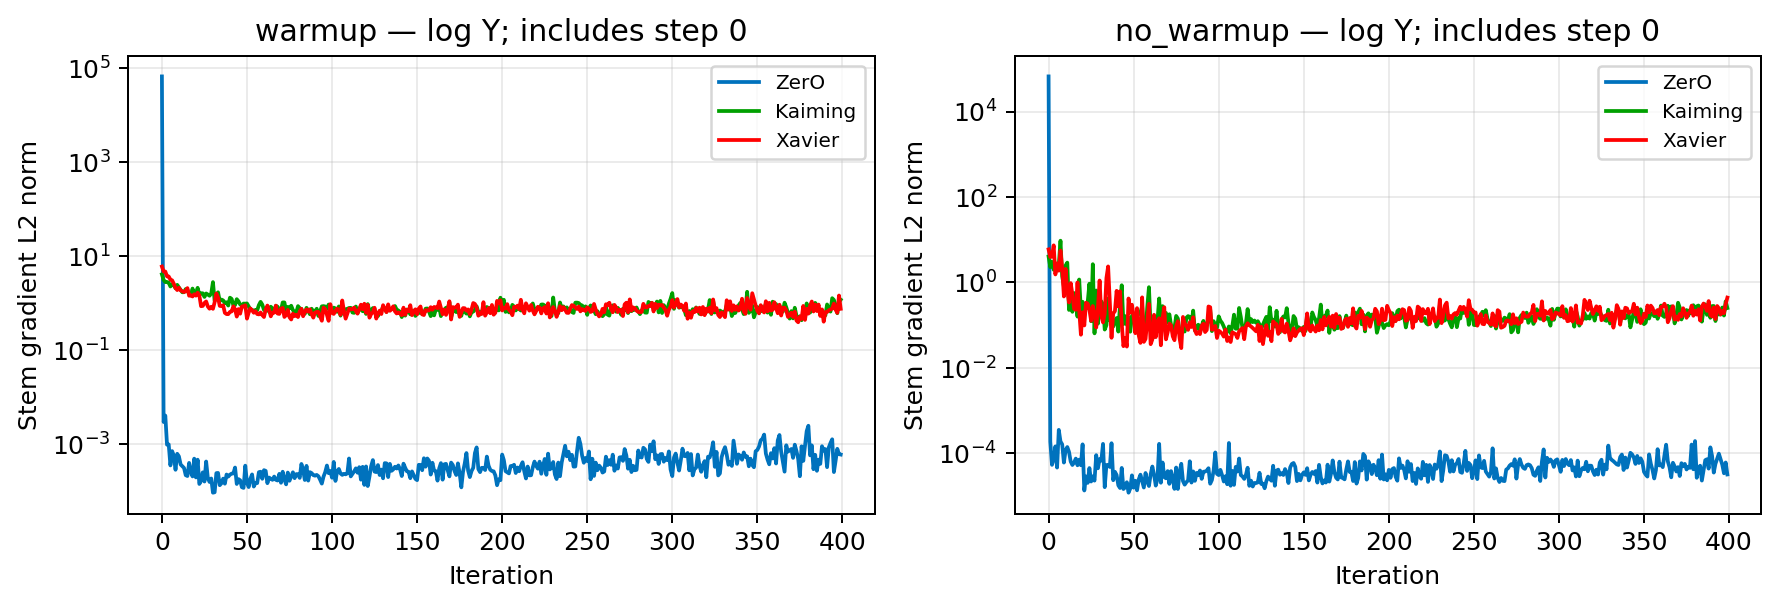

In [5]:
fig = figure8(ROOT, GRADIENT_ROOT)
display(fig)
plt.close(fig)
from collections import defaultdict
counts, hashes = defaultdict(int), defaultdict(set)
for r in load_gradient_rows(GRADIENT_ROOT):
    counts[(r["method"], r["mode"], r["seed"])] += 1
    hashes[(r["seed"], r["step"])].add(r["batch_sha256"])
print("Фактически измерено:", dict(counts))
assert all(len(v) == 1 for v in hashes.values()), "Batches/augmentation differ"
print("Все сохранённые batch hashes совпадают:", bool(hashes))
image = BASE / "runs/plots/figure8-logscale.png"
if image.exists():
    display(Markdown("**Диагностика: логарифмическая шкала, все шаги включая 0.**"))
    display(DisplayImage(filename=str(image)))

## Кривые обучения и стоимость вычислений

**Истории эпох отсутствуют. Показан импортированный график; final metrics берутся из summary.csv.**

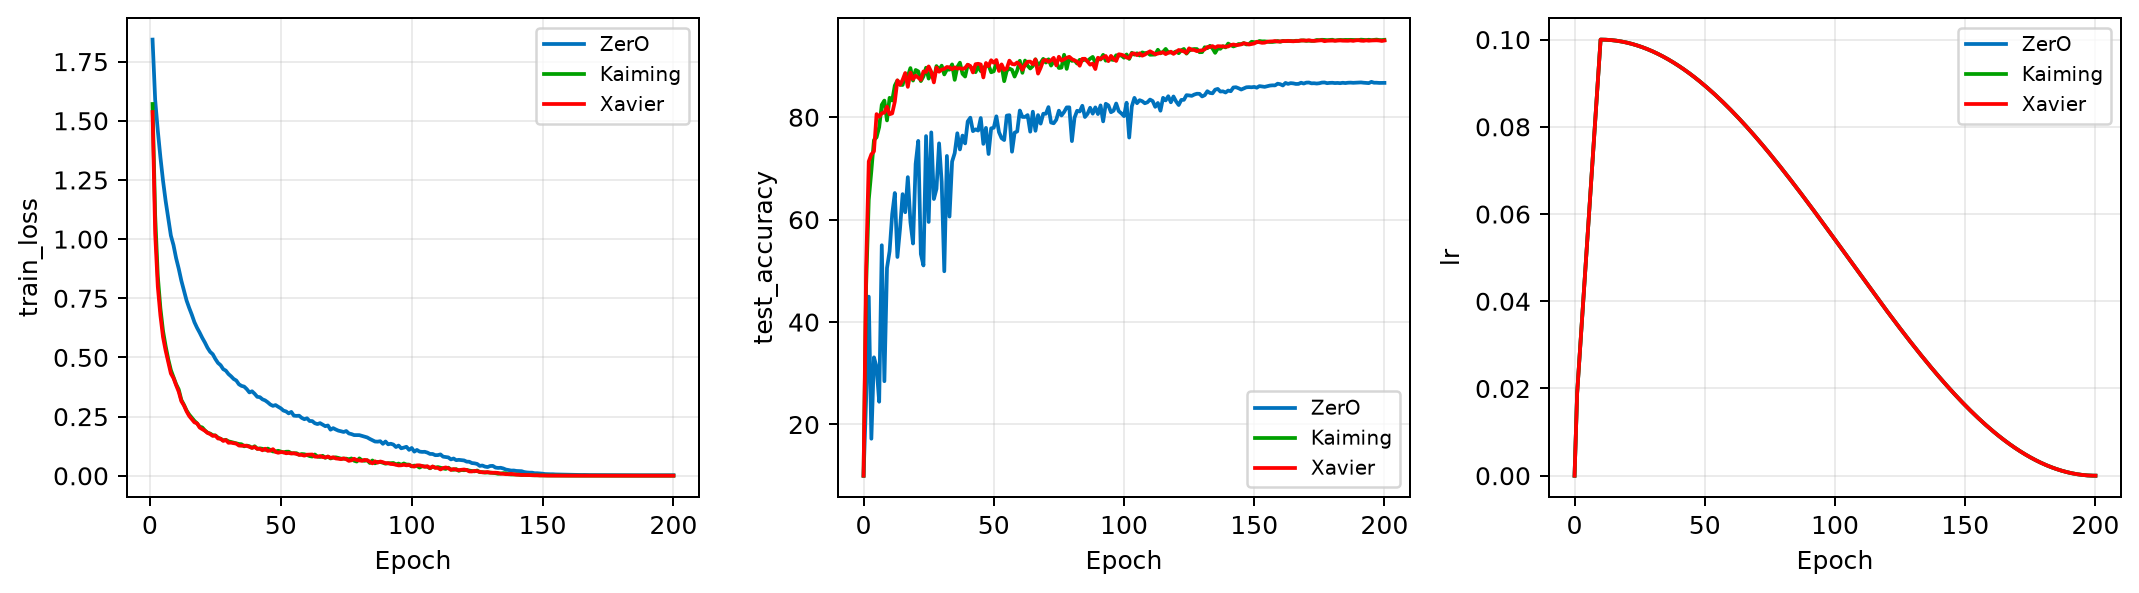

In [6]:
try:
    fig = training_curves(ROOT)
    display(fig)
    plt.close(fig)
except FileNotFoundError as error:
    display(Markdown("**Истории эпох отсутствуют. Показан импортированный график; final metrics берутся из summary.csv.**"))
    image = ROOT / "plots/training.png"
    if image.exists():
        display(DisplayImage(filename=str(image)))
    else:
        print(error)

## Интерпретация

Небольшое отличие средних не доказывает превосходство метода. Stable rank не равен numerical rank или Tucker rank; низкий stable rank не доказывает механизм GLRL. Возможные причины расхождений — неизвестные архитектура/preprocessing/scheduler авторов, версии библиотек, режим детерминизма и различия ранней динамики.

Figure 4 с изменением глубины, ResNet-50 и Transformer исключены. MNIST Figure 3 анализируется отдельно в mlp_ZeRO.ipynb. Недостающие результаты не дорисовываются.

In [7]:
display(Markdown("[Отчёт о воспроизведении (PDF)](../REPORT.pdf)"))

[Отчёт о воспроизведении (PDF)](../REPORT.pdf)